In [2]:
from IPython.display import Image, display

# From visual evidence to feature selection for Titanic survival

Exploratory visualisation can guide both which predictors enter a survival model and how they are represented. Using 891 labelled training passengers, this report combines survival comparisons, stratified patterns and missingness to distinguish promising associations from potentially overlapping information and practical data constraints. Each selected visualisation addresses a different modelling decision.

The joint comparison of sex and passenger class provides a starting point (Figure 1). First-class survival is 96.8% for females and 36.9% for males, compared with 50.0% and 13.5% respectively in third class. Unlike separate passenger counts, these within-group proportions reveal sex differences within class and class differences within sex. Both variables therefore merit inclusion as baseline candidates, while the varying contrasts motivate testing an interaction rather than assuming a uniform relationship.

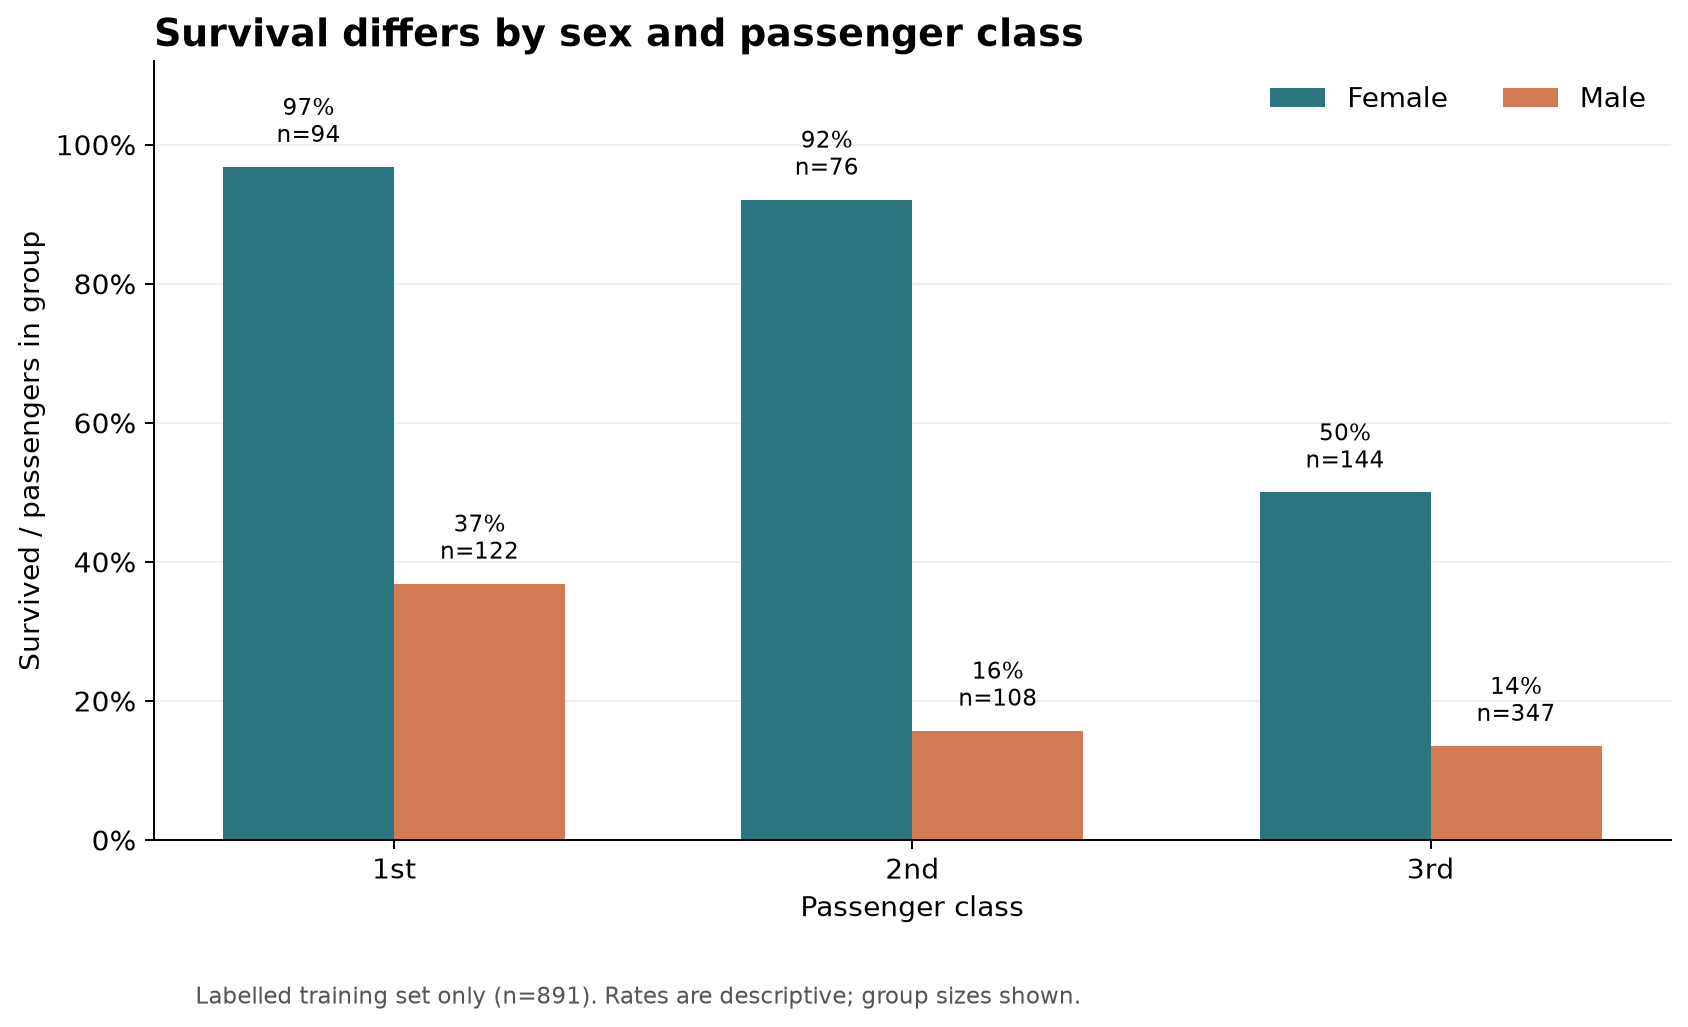

In [3]:
display(Image(filename='figures/q5_01_sex_class.png'))

*Figure 1. Survival by sex and passenger class, labelled training data.*

Once class is identified as informative, the relevant question for Fare is whether it offers information beyond class. Across overall fare quartiles, survival rises from 19.7% to 58.1%, but this gradient may partly reflect class composition. Stratifying fare groups by Pclass helps examine the relationship within class (Figure 2): first-class survival rises from 46.3% in the lowest quartile to 73.6% in the highest, whereas the third-class pattern is much flatter. This supports evaluating Fare alongside Pclass, but neither establishes an independent contribution nor justifies removing it as redundant. Unequal group sizes, including only eight passengers in one second-class group, further limit interpretation.

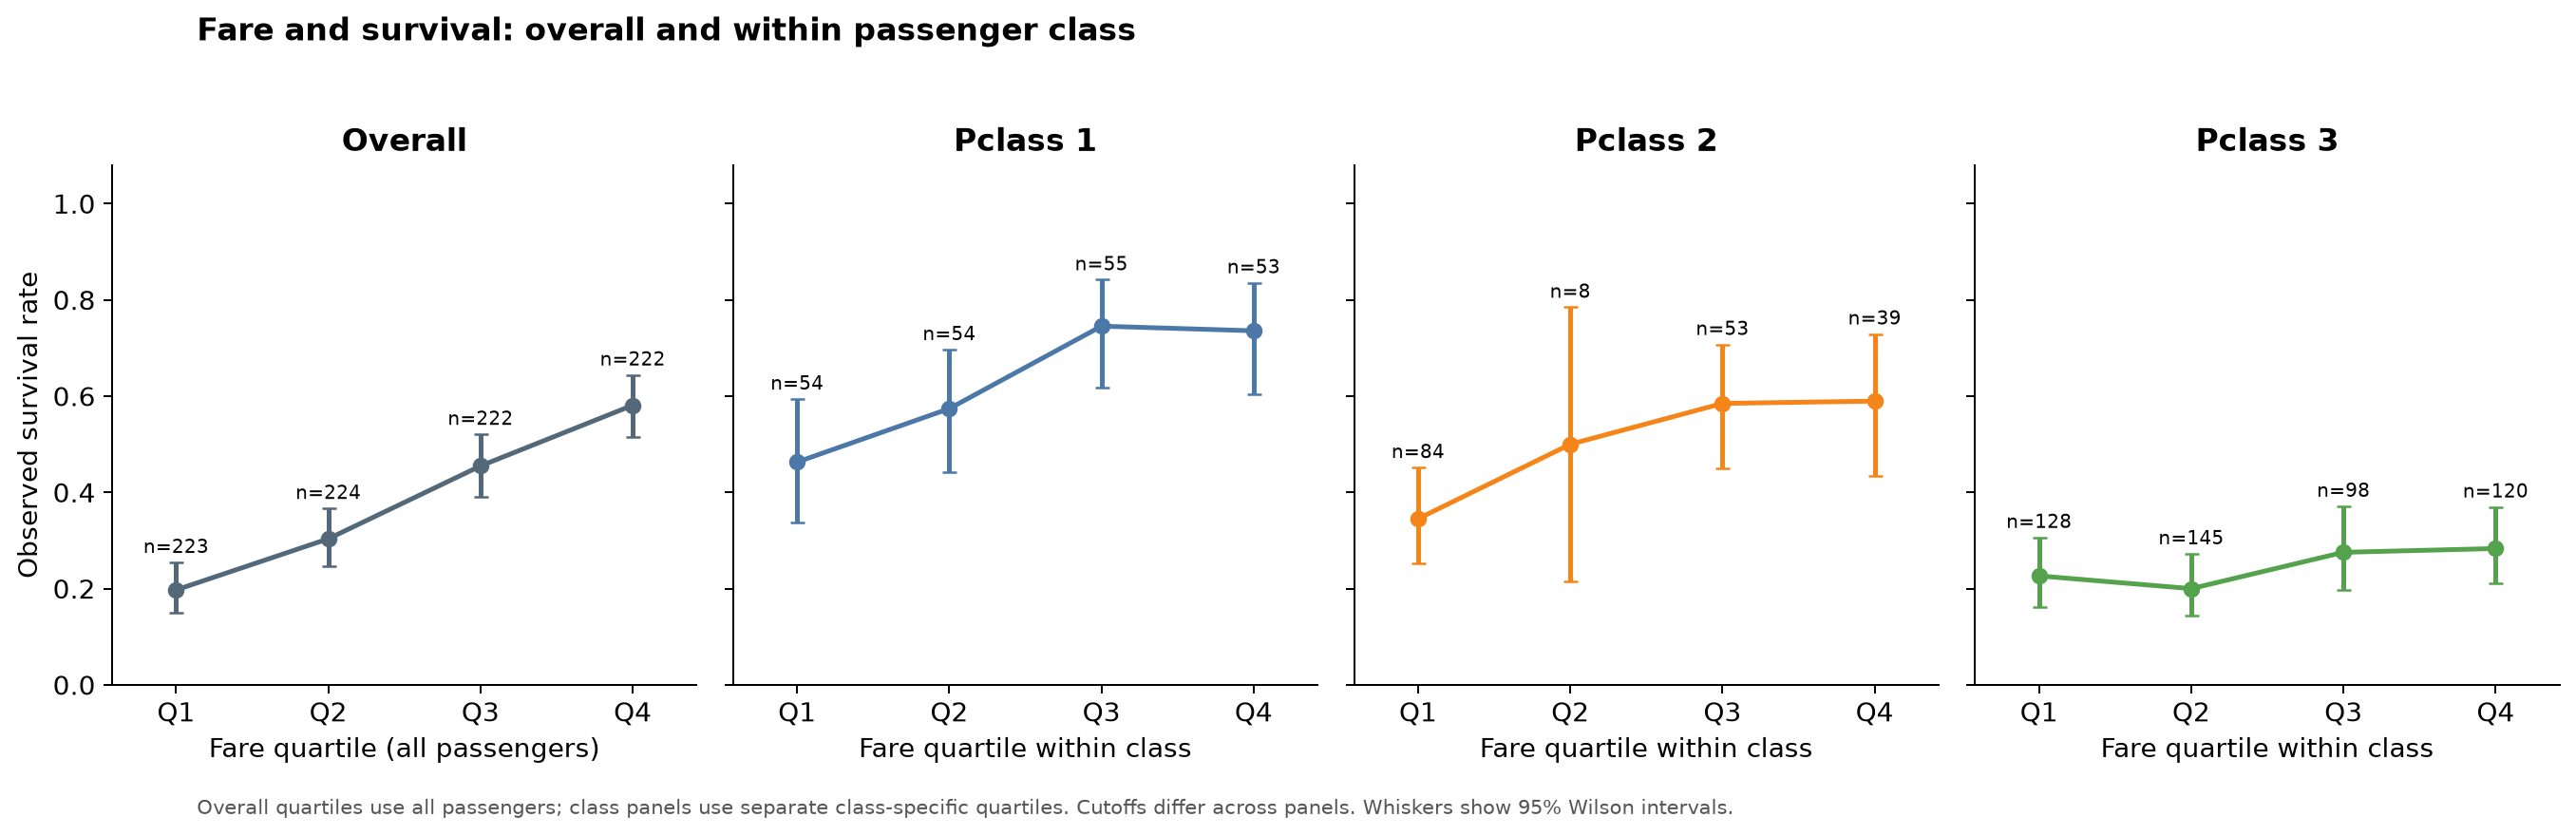

In [4]:
display(Image(filename='figures/q5_02_fare_class.png'))

*Figure 2. Survival by global and class-specific fare quartiles; cutoffs differ across panels. Whiskers show 95% Wilson intervals.*

Representation matters as well as inclusion. Among passengers with recorded ages, the age-band comparison shows higher observed survival among children, at 58.0% for ages 0–12, but does not establish a simple linear relationship (Figure 3). Similarly, survival peaks at 57.9% for recorded family sizes of two to four, compared with 30.4% for passengers without recorded relatives and 16.1% for sizes of at least five (Figure 4). Together, these patterns motivate testing flexible age effects and a family-size feature derived from SibSp + Parch + 1. The grouped plots do not identify optimal cut-offs, particularly with only 22 passengers older than 60.

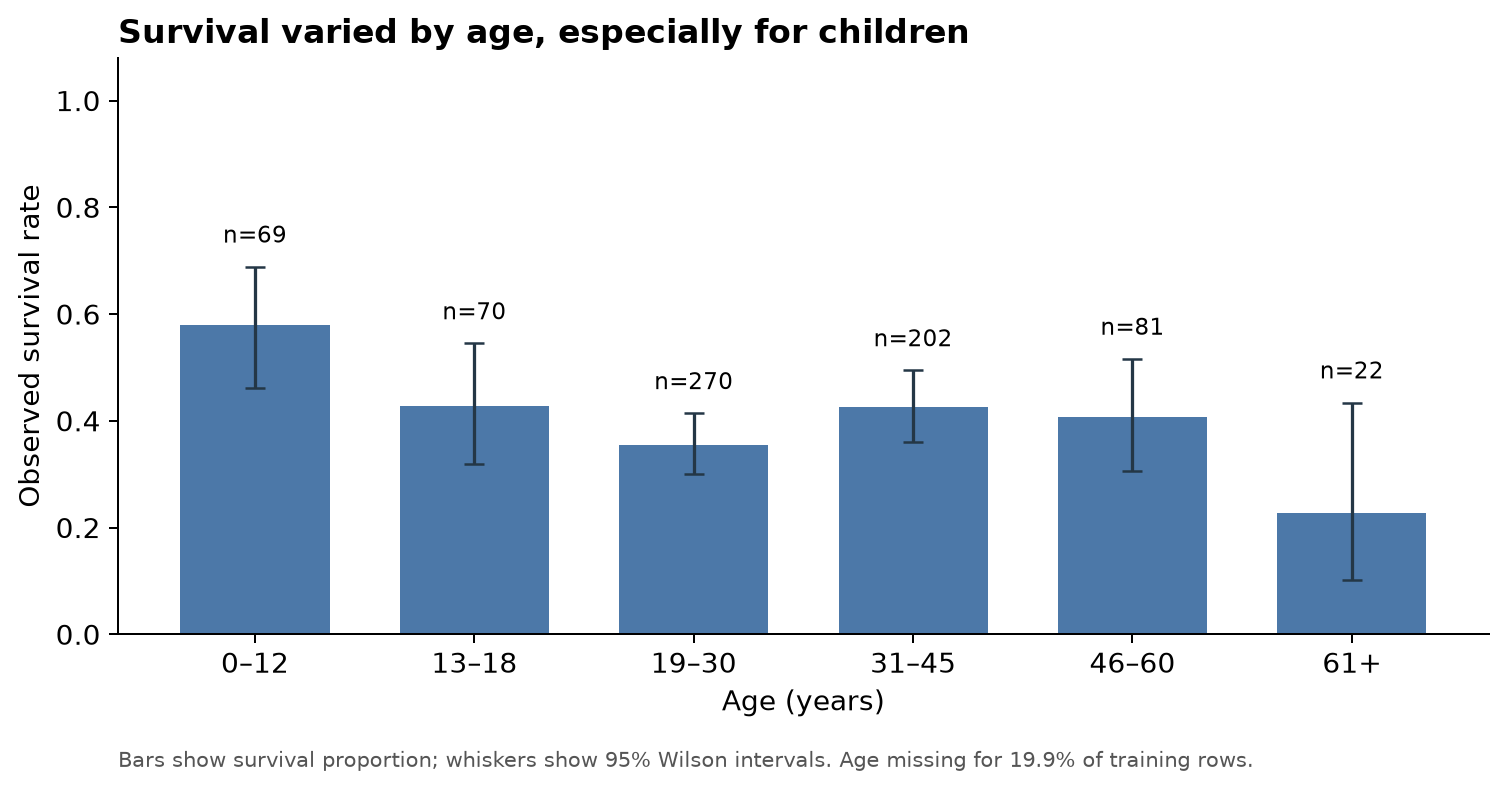

In [5]:
display(Image(filename='figures/q5_03_age.png'))

*Figure 3. Survival across six age bands among passengers with recorded age; whiskers are 95% Wilson intervals.*

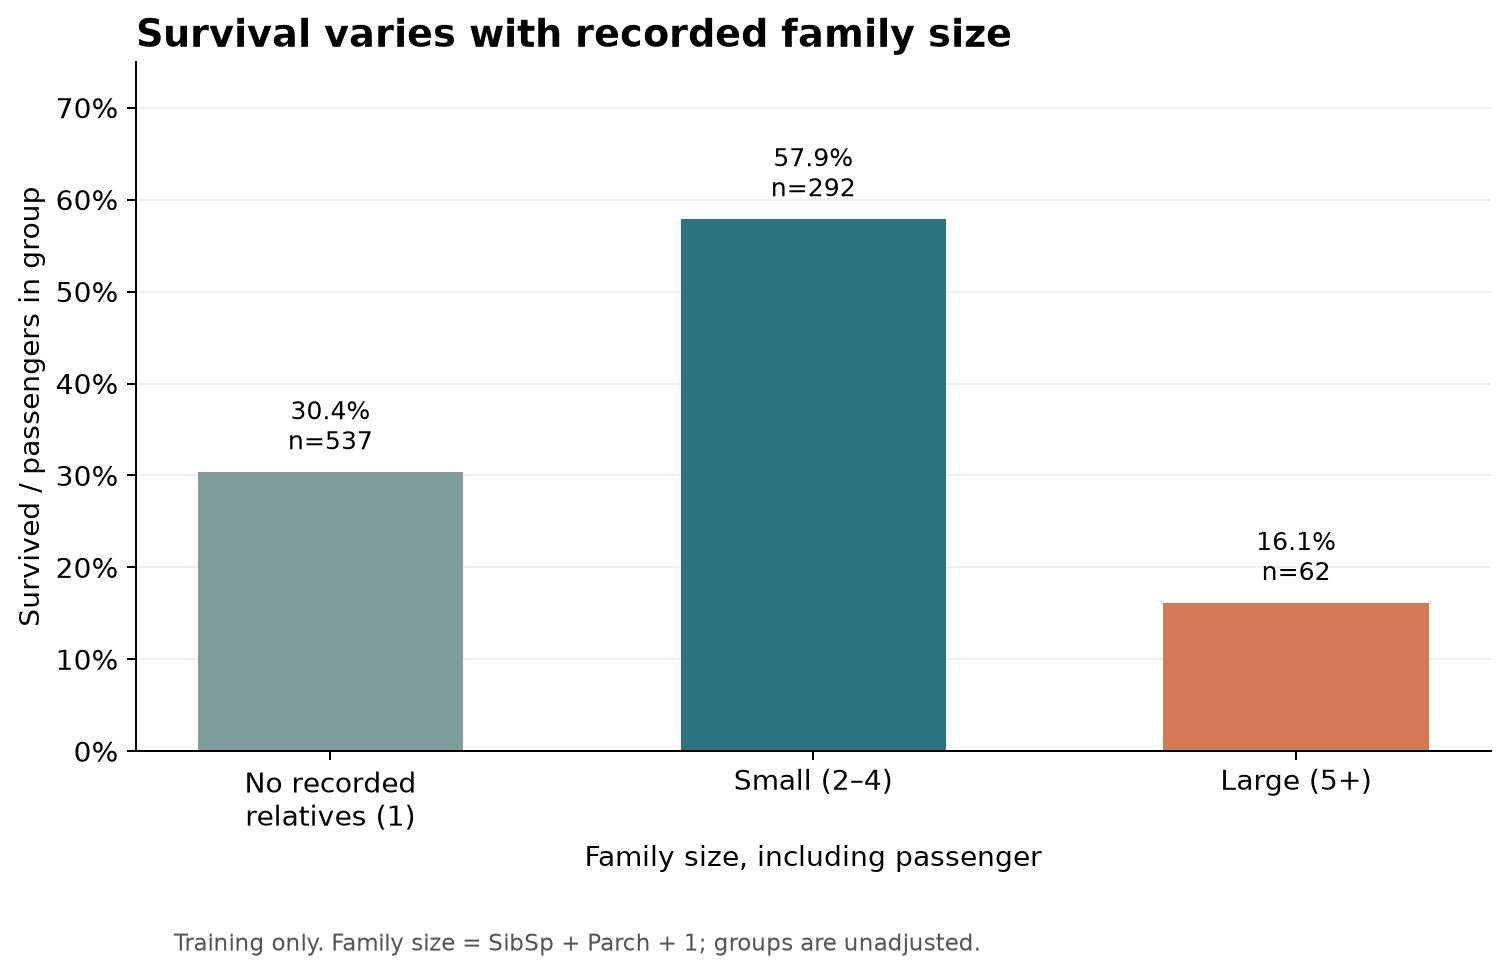

In [6]:
display(Image(filename='figures/q5_04_family.png'))

*Figure 4. Survival by recorded family size, including the passenger.*

These candidates must also be usable. Age is missing for 19.9% of training and 20.6% of test passengers, while Cabin is missing for 77.1% and 78.2% respectively (Figure 5). Training survival is 66.7% with Cabin recorded and 30.0% when missing; because Cabin availability varies by class, a missingness indicator should be evaluated alongside Pclass (Figure 5). Age therefore requires an explicit missing-data strategy; raw Cabin warrants caution because coverage is sparse. Imputation, missingness indicators and derived cabin features remain alternatives to evaluate, since availability alone does not establish predictive value. The unlabelled test set is used only for this availability comparison.

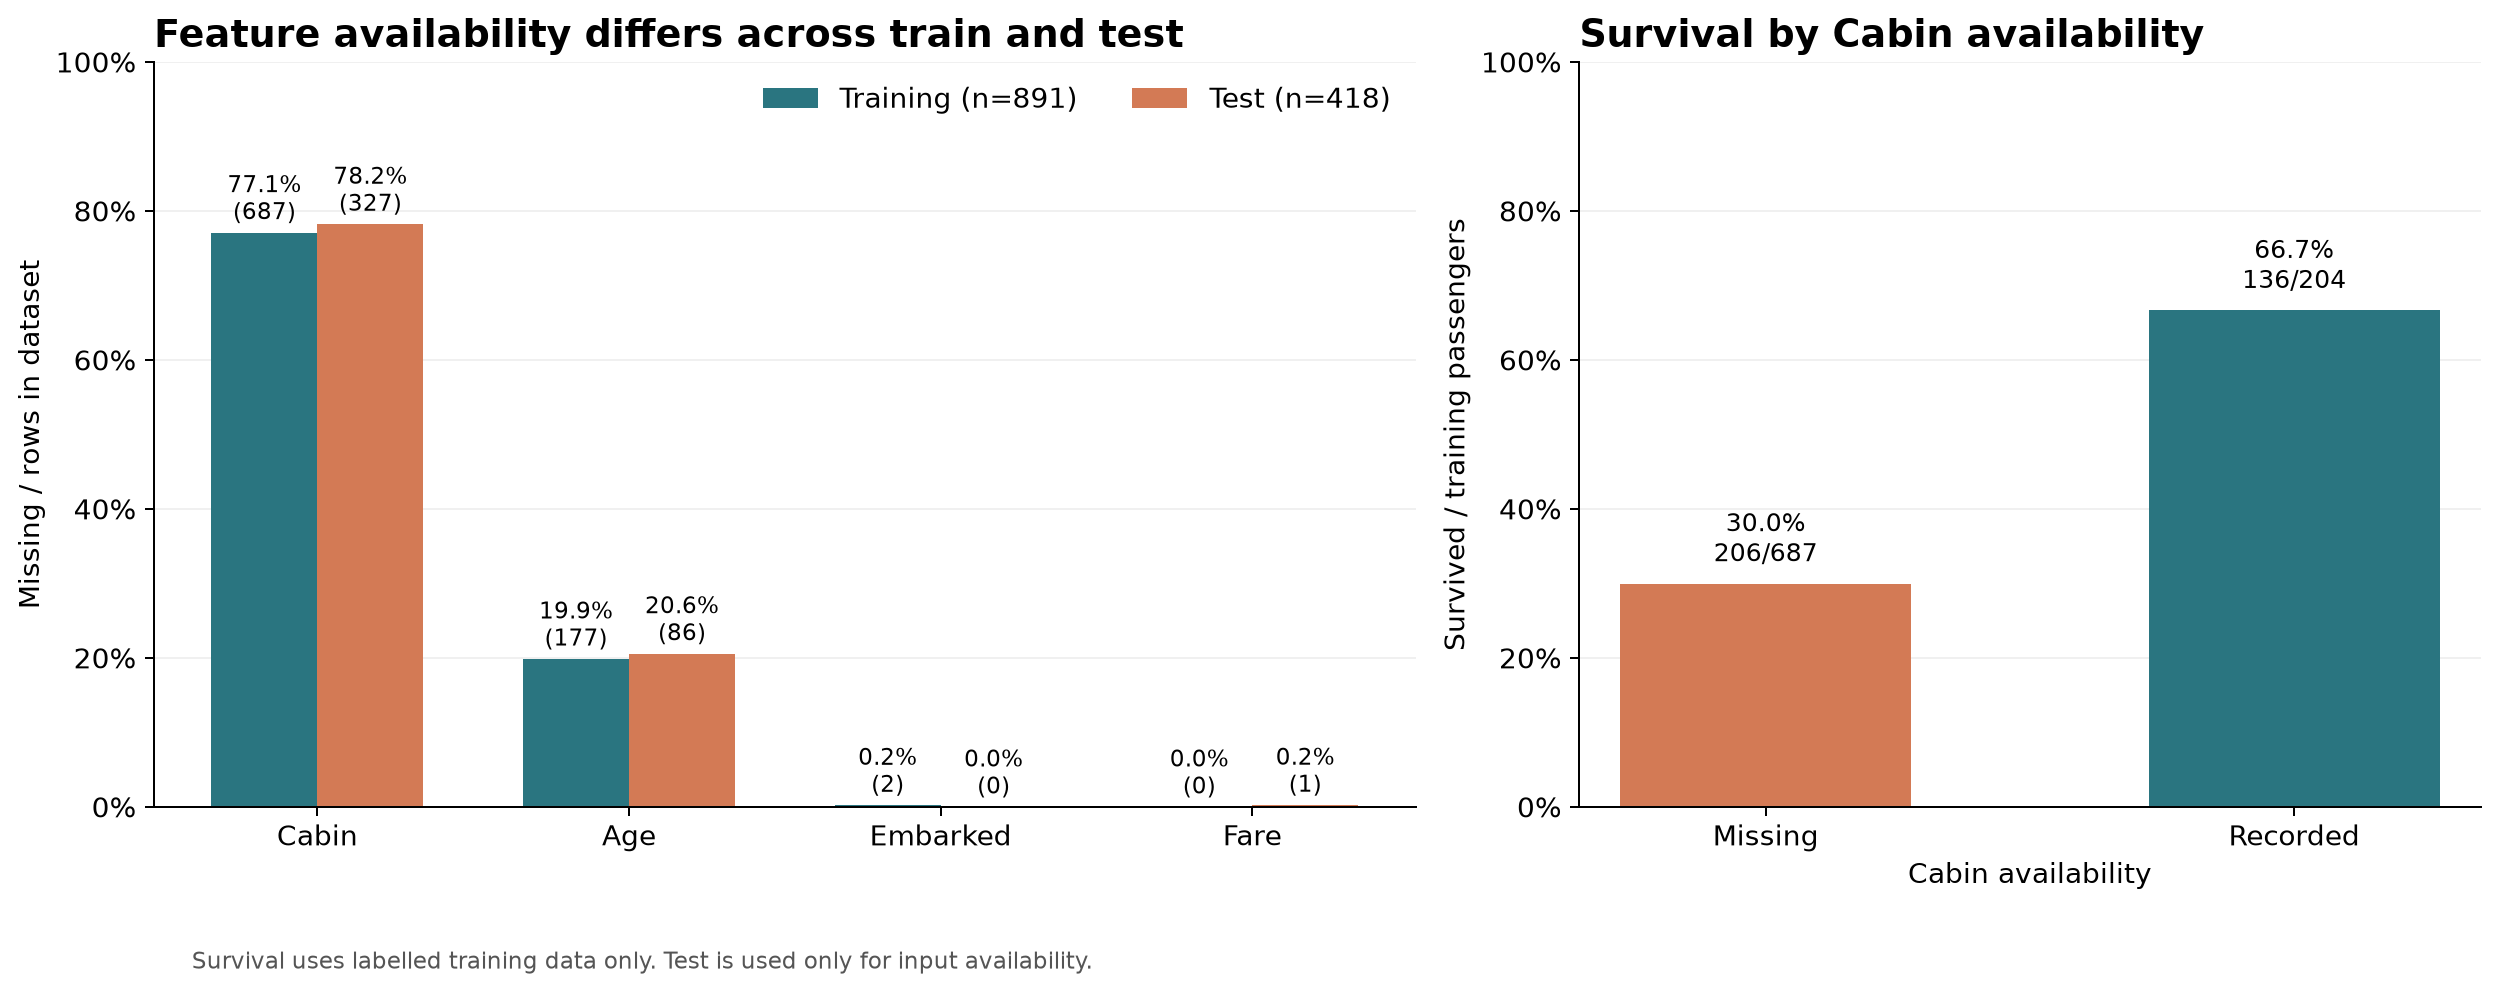

In [7]:
display(Image(filename='figures/q5_05_missingness.png'))

*Figure 5. Missing inputs in train and unlabelled test, and survival by Cabin availability in training.*

The visual evidence thus supports a provisional shortlist and alternative representations, rather than a final feature ranking. Subsequent validation should compare their incremental predictive value, fitting preprocessing within training folds. These exploratory associations neither establish causality nor guarantee improved predictions.